## Clasificacion IRIS

El dataset contiene 150 registros de flores de iris, distribuidos en tres especies. Cada registro incluye cuatro características numéricas de la flor.

Primeros registros:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Cantidad de registros: 150

Distribución de clases:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Accuracy: 0.9333

Reporte de clasificación:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                    

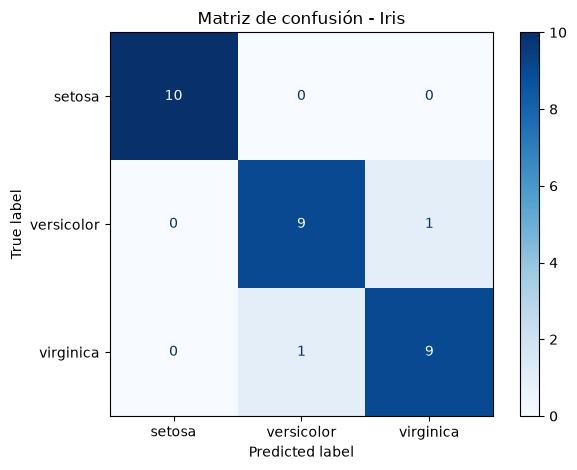


Especie predicha: setosa
Probabilidades por especie:
setosa: 98.08%
versicolor: 1.92%
virginica: 0.00%


: 

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Cargar el dataset
iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

# 2. Explorar los datos
df = X.copy()
df["species"] = y.map(
    dict(enumerate(iris.target_names))
)

print("Primeros registros:")
print(df.head())

print("\nCantidad de registros:", len(df))
print("\nDistribución de clases:")
print(df["species"].value_counts())

# 3. Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Crear y entrenar el modelo
modelo = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

modelo.fit(X_train, y_train)

# 5. Realizar predicciones
y_pred = modelo.predict(X_test)

# 6. Evaluar el modelo
accuracy = accuracy_score(y_test, y_pred)

print(f"\nAccuracy: {accuracy:.4f}")
print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

# 7. Visualizar la matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Matriz de confusión - Iris")
plt.tight_layout()
plt.show()

# 8. Clasificar una nueva flor
nueva_flor = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

prediccion = modelo.predict(nueva_flor)[0]
probabilidades = modelo.predict_proba(nueva_flor)[0]

print("\nEspecie predicha:", iris.target_names[prediccion])
print("Probabilidades por especie:")

for especie, probabilidad in zip(
    iris.target_names, probabilidades
):
    print(f"{especie}: {probabilidad:.2%}")


## 1. Dataset propuesto: Iris

[Iris setosa (arctic iris): a wild iris in Japan | Iris setos… | Flickr](https://images.openai.com/static-rsc-4/FIE2bQU5Vp2JRQ7LFQTxH426TC5EXly1Bk1LF0gmfY3qZ1dHfphs8NGMK8G-U6z5ALtAzafePNfEYk14vejuVZoZWxRONOgc4OqXBFrAnmRDM8_F9E56zLEhvNu0ZVaw7EJryWoEBexdYRrKee_ucf3zfmanPftNsBsGdGWazeA?purpose=inline)

[Blue Flag Iris Perennial - Iris versicolor - Gallon Pot - Hirt's Gardens](https://images.openai.com/static-rsc-4/CFABgeVIOVUtFDORo_cs7ge-QLP7gTnwlkkfpUzepm_un1MI_ktwG06Ga6mKoDLeOv02wZMmbIPuMVPfkk21ciD8jHBLR82AG2GD-Ny-SHIlmdw3d84x6vMQxJeGiZvsQexIq2hTWRi-RziPZDBIZBaq4t9waH0-RdGwdKtMBC8?purpose=inline)

[File:Iris virginica.jpg - Wikimedia Commons](https://images.openai.com/static-rsc-4/6obnNgnLvSosyk5VJOJXDeYOnsKCChuQbBD4nG4NCBvd8XjV0arerUQmqQ_qgpcCDs3fixipbnVXp3rGgSkbyPNolNdbG2j0uj_wb0XIqTSCVM35kPhGeSLpkbwJJ7r-iiohOXKJdrotz2bT9TrH6OqCaB1kVYVR8ojZVTUlnM0?purpose=inline)

El dataset contiene 150 registros de flores de iris, distribuidos en tres especies. Cada registro incluye cuatro características numéricas de la flor.

| Variable       | Descripción                   |
| -------------- | ----------------------------- |
| `sepal length` | Longitud del sépalo, en cm    |
| `sepal width`  | Ancho del sépalo, en cm       |
| `petal length` | Longitud del pétalo, en cm    |
| `petal width`  | Ancho del pétalo, en cm       |
| `species`      | Especie que se desea predecir |

Las tres clases son `setosa`, `versicolor` y `virginica`.

Objetivo: entrenar un modelo que, a partir de las cuatro medidas de una flor, prediga a qué especie pertenece.

## 2. Algoritmo de clasificación en Python

Vamos a implementar una regresión logística multiclase, utilizando `scikit-learn`. Aunque su nombre incluye regresión, también es un algoritmo ampliamente utilizado para clasificación.

Instalá las dependencias:

```
pip install scikit-learn pandas matplotlib
```


## 3. Flujo de trabajo del modelo

1\. Carga de datos

150 flores · 4 características · 3 clases

2\. Preparación de datos

Separación 80 % entrenamiento / 20 % prueba

3\. Escalado y entrenamiento

StandardScaler + Regresión logística

4\. Predicción

Especie estimada y probabilidades por clase

5\. Evaluación

Accuracy, precision, recall, F1-score y matriz de confusión

## 4. ¿Cómo interpretar los resultados?

| Métrica             | Qué indica                                                      |
| ------------------- | --------------------------------------------------------------- |
| Accuracy            | Porcentaje total de predicciones correctas.                     |
| Precision           | De las predicciones de una clase, cuántas fueron correctas.     |
| Recall              | De los casos reales de una clase, cuántos fueron identificados. |
| F1-score            | Media armónica entre precision y recall.                        |
| Matriz de confusión | Muestra las clases reales frente a las predichas.               |

La división estratificada mantiene una proporción similar de las tres especies en entrenamiento y prueba. El escalado se ajusta exclusivamente con los datos de entrenamiento gracias a `Pipeline`, evitando filtrar información del conjunto de prueba.

El dataset Iris suele producir resultados de accuracy elevados, aunque el valor exacto depende de la división y del modelo.

## 5. Próximos pasos para aprender clasificación

Te recomiendo avanzar en este orden:

1. Regresión logística: el modelo desarrollado aquí.
2. Árbol de decisión: reglas de clasificación fáciles de interpretar.
3. Random Forest: combinación de múltiples árboles.
4. K-Nearest Neighbors (KNN): clasificación por similitud entre registros.
5. Comparación de modelos: evaluar todos con las mismas particiones y métricas.

Como ejercicio, podés cambiar `LogisticRegression` por `DecisionTreeClassifier` o `RandomForestClassifier` y comparar el rendimiento sobre el mismo dataset. Esto permite comprender cómo distintos algoritmos resuelven un mismo problema de clasificación.